# Anil Singal

# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

THE ABOVE LINK IS JUST FOR REFERENCE - PLEASE DO NOT USE THE DATASET PROVIDED IN THE ABOVE WEBPAGE FOR SOLVING THE ASSIGNMENT.

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [2]:
# Import warnings
import warnings
warnings.filterwarnings("ignore")

In [4]:
# installing the libraries
!pip install numpy==1.26.4
!pip install pandas==2.2.2
!pip install matplotlib==3.10.0
!pip install seaborn==0.13.2

  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'error'


  error: subprocess-exited-with-error
  
  Preparing metadata (pyproject.toml) did not run successfully.
  exit code: 1
  
  [21 lines of output]
  + C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\python.exe C:\Users\Lenovo\AppData\Local\Temp\pip-install-fpckf5an\numpy_f5321a446c354750aa950b508b5e958b\vendored-meson\meson\meson.py setup C:\Users\Lenovo\AppData\Local\Temp\pip-install-fpckf5an\numpy_f5321a446c354750aa950b508b5e958b C:\Users\Lenovo\AppData\Local\Temp\pip-install-fpckf5an\numpy_f5321a446c354750aa950b508b5e958b\.mesonpy-7higwxe1 -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --native-file=C:\Users\Lenovo\AppData\Local\Temp\pip-install-fpckf5an\numpy_f5321a446c354750aa950b508b5e958b\.mesonpy-7higwxe1\meson-python-native-file.ini
  The Meson build system
  Version: 1.2.99
  Source dir: C:\Users\Lenovo\AppData\Local\Temp\pip-install-fpckf5an\numpy_f5321a446c354750aa950b508b5e958b
  Build dir: C:\Users\Lenovo\AppData\Local\Temp\pip-install-fpckf5an\numpy_f5321a

  Using cached pandas-2.2.2.tar.gz (4.4 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'error'


  error: subprocess-exited-with-error
  
  Preparing metadata (pyproject.toml) did not run successfully.
  exit code: 1
  
  [12 lines of output]
  + meson setup C:\Users\Lenovo\AppData\Local\Temp\pip-install-dvrp58xd\pandas_589bba9e85e6424bb813a963a9a878e4 C:\Users\Lenovo\AppData\Local\Temp\pip-install-dvrp58xd\pandas_589bba9e85e6424bb813a963a9a878e4\.mesonpy-bacu986o\build -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --vsenv --native-file=C:\Users\Lenovo\AppData\Local\Temp\pip-install-dvrp58xd\pandas_589bba9e85e6424bb813a963a9a878e4\.mesonpy-bacu986o\build\meson-python-native-file.ini
  The Meson build system
  Version: 1.2.1
  Source dir: C:\Users\Lenovo\AppData\Local\Temp\pip-install-dvrp58xd\pandas_589bba9e85e6424bb813a963a9a878e4
  Build dir: C:\Users\Lenovo\AppData\Local\Temp\pip-install-dvrp58xd\pandas_589bba9e85e6424bb813a963a9a878e4\.mesonpy-bacu986o\build
  Build type: native build
  Project name: pandas
  Project version: 2.2.2
  
  ..\..\meson.build:2:0: ERROR: C


[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 1.26.4
pandas version: 2.2.2
matplotlib version: 3.9.2
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [14]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload


In [15]:
# from google.colab import drive
# drive.mount('/content/drive')

In [16]:
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
#   read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

import os

# --- Config ---
base_location = r"D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\trip_records"
SAMPLE_FRAC = 0.007   # 0.7%
RANDOM_STATE = 42     # for reproducibility
TIMESTAMP_CANDIDATES = ["tpep_pickup_datetime", "lpep_pickup_datetime", "pickup_datetime"]

# --- Helpers ---
def find_timestamp_col(columns):
    for c in TIMESTAMP_CANDIDATES:
        if c in columns:
            return c
    raise KeyError(f"None of the expected timestamp columns found: {TIMESTAMP_CANDIDATES}")

# --- Collect monthly samples then concat at end ---
files = [f for f in os.listdir(base_location) if f.lower().endswith((".parquet", ".parq"))]
files.sort()  # ensure stable processing order

year_samples = []  # store per-month sampled dataframes

for file_name in files:
    try:
        file_path = os.path.join(base_location, file_name)
        print(f"Reading: {file_path}")
        month_data = pd.read_parquet(file_path)  # requires pyarrow or fastparquet
       
        ts_col = find_timestamp_col(month_data.columns)
        # Parse datetime (drop rows where parsing fails)
        month_data[ts_col] = pd.to_datetime(month_data[ts_col], errors="coerce")
        month_data = month_data.dropna(subset=[ts_col])

        # Build date/hour columns
        month_data["date"] = month_data[ts_col].dt.date
        month_data["hour"] = month_data[ts_col].dt.hour

        # Sample within each (date, hour)
        sampled = (
            month_data
            .groupby(["date", "hour"], group_keys=False)
            .apply(lambda g: g.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE)
                   if len(g) > 0 else g.iloc[[]])
        )

        # (Optional) If you don't want date/hour in the final output:
        sampled = sampled.drop(columns=["date", "hour"])

        print(f"  Original: {month_data.shape}, Sampled: {sampled.shape}")
        year_samples.append(sampled)

    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

# Combine all months
df = pd.concat(year_samples, ignore_index=True)
print("Final sampled dataframe shape:", df.shape)


Reading: D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\trip_records\2023-1.parquet
  Original: (3041714, 21), Sampled: (21288, 19)
Reading: D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\trip_records\2023-10.parquet
  Original: (3485185, 21), Sampled: (24408, 19)
Reading: D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\trip_records\2023-11.parquet
  Original: (3302857, 21), Sampled: (23115, 19)
Reading: D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\trip_records\2023-12.parquet
  Original: (3333925, 21), Sampled: (23352, 19)
Reading: D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\trip_records\2023-2.parquet
  Original: (3374086, 21), Sampled: (23617, 19)
Reading: D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\trip_records\2023-3.parquet
  Original: (3275796, 21), Sampled: (22939,

In [17]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,Airport_fee
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1.0,7.74,1.0,N,138,256,2,32.40,6.0,0.5,0.00,0.0,1.0,41.15,0.0,1.25,NaN
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2.0,1.24,1.0,N,161,237,1,7.90,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.00,NaN
2,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3.0,1.44,1.0,N,237,141,2,11.40,1.0,0.5,0.00,0.0,1.0,16.40,2.5,0.00,NaN
3,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1.0,0.54,1.0,N,143,142,2,6.50,1.0,0.5,0.00,0.0,1.0,11.50,2.5,0.00,NaN
4,2,2023-01-01 00:43:00,2023-01-01 01:01:00,NaN,19.24,NaN,None,66,107,0,25.64,0.0,0.5,5.93,0.0,1.0,35.57,NaN,NaN,NaN


In [18]:
df.shape

(265487, 20)

After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [20]:
# Store the df in csv/parquet
#df.to_parquet("nyc_taxi_year_sample_0p7pct.parquet", index=False)
#df.to_csv("nyc_taxi_year_sample_0p7pct.csv", index=False)

## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [23]:
# Load the new data file
df = pd.read_csv(r"nyc_taxi_year_sample_0p7pct.csv")


In [24]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,Airport_fee
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1.0,7.74,1.0,N,138,256,2,32.40,6.0,0.5,0.00,0.0,1.0,41.15,0.0,1.25,NaN
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2.0,1.24,1.0,N,161,237,1,7.90,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.00,NaN
2,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3.0,1.44,1.0,N,237,141,2,11.40,1.0,0.5,0.00,0.0,1.0,16.40,2.5,0.00,NaN
3,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1.0,0.54,1.0,N,143,142,2,6.50,1.0,0.5,0.00,0.0,1.0,11.50,2.5,0.00,NaN
4,2,2023-01-01 00:43:00,2023-01-01 01:01:00,NaN,19.24,NaN,NaN,66,107,0,25.64,0.0,0.5,5.93,0.0,1.0,35.57,NaN,NaN,NaN


In [25]:
df.shape

(265487, 20)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265487 entries, 0 to 265486
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               265487 non-null  int64  
 1   tpep_pickup_datetime   265487 non-null  object 
 2   tpep_dropoff_datetime  265487 non-null  object 
 3   passenger_count        256656 non-null  float64
 4   trip_distance          265487 non-null  float64
 5   RatecodeID             256656 non-null  float64
 6   store_and_fwd_flag     256656 non-null  object 
 7   PULocationID           265487 non-null  int64  
 8   DOLocationID           265487 non-null  int64  
 9   payment_type           265487 non-null  int64  
 10  fare_amount            265487 non-null  float64
 11  extra                  265487 non-null  float64
 12  mta_tax                265487 non-null  float64
 13  tip_amount             265487 non-null  float64
 14  tolls_amount           265487 non-nu

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [42]:
# Fix the index and drop any columns that are not needed
df.reset_index(drop=True, inplace=True)

**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [45]:
# Cheking the values
print(df[['airport_fee', 'Airport_fee']].describe())
print(df[['airport_fee', 'Airport_fee']].isna().sum())

#Combining the two airport columns
df['airport_fee'] = df['airport_fee'].fillna(df['Airport_fee'])

## Dropping the Airport_fee column
df.drop(columns = ['Airport_fee'], inplace=True)

        airport_fee    Airport_fee
count  20782.000000  235874.000000
mean       0.109349       0.145987
std        0.353179       0.473234
min        0.000000      -1.750000
25%        0.000000       0.000000
50%        0.000000       0.000000
75%        0.000000       0.000000
max        1.250000       1.750000
airport_fee    244705
Airport_fee     29613
dtype: int64


**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [48]:
# check where values of fare amount are negative
negative_fare = df[df['fare_amount']<0]
print(negative_fare)


Empty DataFrame
Columns: [VendorID, tpep_pickup_datetime, tpep_dropoff_datetime, passenger_count, trip_distance, RatecodeID, store_and_fwd_flag, PULocationID, DOLocationID, payment_type, fare_amount, extra, mta_tax, tip_amount, tolls_amount, improvement_surcharge, total_amount, congestion_surcharge, airport_fee]
Index: []


Did you notice something different in the `RatecodeID` column for above records?

In [51]:
# Analyse RatecodeID for the negative fare amounts
negative_ratecode = df[df['RatecodeID']<0]
print(negative_ratecode)

Empty DataFrame
Columns: [VendorID, tpep_pickup_datetime, tpep_dropoff_datetime, passenger_count, trip_distance, RatecodeID, store_and_fwd_flag, PULocationID, DOLocationID, payment_type, fare_amount, extra, mta_tax, tip_amount, tolls_amount, improvement_surcharge, total_amount, congestion_surcharge, airport_fee]
Index: []


In [53]:
# Find which columns have negative values
negative_col = (df.select_dtypes(include=['number'])<0).sum()
print(negative_col)
                

VendorID                  0
passenger_count           0
trip_distance             0
RatecodeID                0
PULocationID              0
DOLocationID              0
payment_type              0
fare_amount               0
extra                     1
mta_tax                  11
tip_amount                0
tolls_amount              0
improvement_surcharge    11
total_amount             11
congestion_surcharge      6
airport_fee               2
dtype: int64


In [55]:
# fix these negative values
col_fix = [
    'extra',
    'mta_tax',
    'improvement_surcharge',
    'congestion_surcharge',
    'airport_fee'
]

for col in col_fix:
    df.loc[df[col]< 0, col] = 0

## Removed rows where total_amount is negative
df = df[df['total_amount']>=0]

In [57]:
df.head(1)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1.0,7.74,1.0,N,138,256,2,32.4,6.0,0.5,0.0,0.0,1.0,41.15,0.0,1.25


### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [61]:
# Find the proportion of missing values in each column
missing_percent = df.isnull().mean() * 100
print(missing_percent)

VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          3.326478
trip_distance            0.000000
RatecodeID               3.326478
store_and_fwd_flag       3.326478
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     3.326478
airport_fee              3.326478
dtype: float64


**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [64]:
# Display the rows with null values
df[df.isna().any(axis = 1)]

# Impute NaN values in 'passenger_count'
df['passenger_count'] = df['passenger_count'].fillna(df['passenger_count'].median())

Did you find zeroes in passenger_count? Handle these.

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [68]:
# Fix missing values in 'RatecodeID'
df['RatecodeID'] = df['RatecodeID'].fillna(df['RatecodeID'].mode()[0])

**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [71]:
# handle null values in congestion_surcharge
df['congestion_surcharge'] = df['congestion_surcharge'].fillna(df['congestion_surcharge'].mode()[0])


Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [74]:
# Handle any remaining missing values
df['store_and_fwd_flag'] = df['store_and_fwd_flag'].fillna(df['store_and_fwd_flag'].mode()[0])
df['airport_fee'] = df['airport_fee'].fillna(0)

In [76]:
df.isnull().sum()

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
airport_fee              0
dtype: int64

In [78]:
df.head(2)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1.0,7.74,1.0,N,138,256,2,32.4,6.0,0.5,0.00,0.0,1.0,41.15,0.0,1.25
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2.0,1.24,1.0,N,161,237,1,7.9,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.00


### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [82]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns
df.describe()

cols = ['passenger_count','trip_distance','fare_amount','total_amount','trip_distance','payment_type']

for col in cols:
    print(col)
    print("Min", df[col].min())
    print("Max", df[col].max())
    print()
    

passenger_count
Min 0.0
Max 9.0

trip_distance
Min 0.0
Max 22528.82

fare_amount
Min 0.0
Max 910.0

total_amount
Min 0.0
Max 911.0

trip_distance
Min 0.0
Max 22528.82

payment_type
Min 0
Max 4



**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [87]:
# remove passenger_count > 6
df = df[df["passenger_count"] < 6 ] 


In [89]:
# Continue with outlier handling
df = df[~((df['trip_distance']< 0.1) & (df['fare_amount'] > 300))]

df = df[~(
    (df['trip_distance'] == 0) &
    (df['fare_amount'] == 0) &
    (df['PULocationID'] != df['DOLocationID'])
)]

df = df[df['trip_distance'] < 250]

In [95]:
df.tail()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
265482,1,2023-09-30 23:02:41,2023-09-30 23:19:28,1.0,3.40,1.0,N,107,141,1,19.1,3.5,0.5,7.20,0.0,1.0,31.30,2.5,0.0
265483,2,2023-09-30 23:16:43,2023-09-30 23:40:51,1.0,5.13,1.0,N,264,264,1,28.2,1.0,0.5,6.64,0.0,1.0,39.84,2.5,0.0
265484,1,2023-09-30 23:04:38,2023-09-30 23:15:39,1.0,1.20,1.0,N,137,170,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
265485,2,2023-09-30 23:59:52,2023-10-01 00:45:20,1.0,7.06,1.0,N,68,129,1,44.3,1.0,0.5,2.00,0.0,1.0,51.30,2.5,0.0
265486,2,2023-09-30 23:23:30,2023-09-30 23:33:41,2.0,1.57,1.0,N,148,90,1,11.4,1.0,0.5,3.28,0.0,1.0,19.68,2.5,0.0


In [99]:
# Do any columns need standardising?
df['passenger_count'] = df['passenger_count'].astype(int)
df['RatecodeID'] = df['RatecodeID'].astype(int)
df.dtypes

VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count            int32
trip_distance            float64
RatecodeID                 int32
store_and_fwd_flag        object
PULocationID               int64
DOLocationID               int64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
airport_fee              float64
dtype: object

## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [102]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

In [108]:
# Create time & duration features
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'], errors='coerce')
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], errors='coerce')

df['trip_duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds()/60
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['pickup_dayofweek'] = df['tpep_pickup_datetime'].dt.day_name()
df['pickup_month'] = df['tpep_pickup_datetime'].dt.month

<Axes: title={'center': 'Taxi Pickups by Hour'}, xlabel='pickup_hour'>

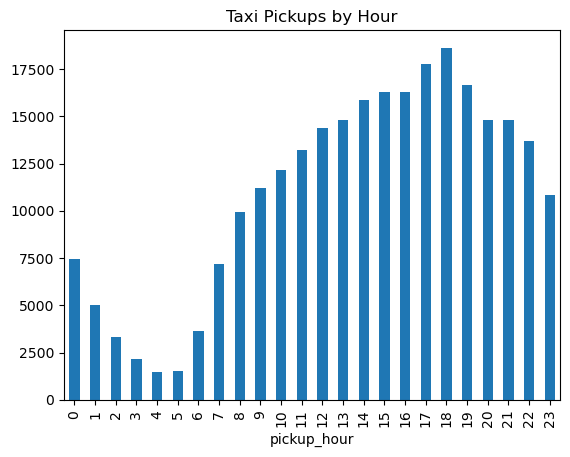

In [112]:
# Find and show the hourly trends in taxi pickups
hourly_trips = df.groupby('pickup_hour').size()

hourly_trips.plot(kind = "bar", title = 'Taxi Pickups by Hour')

<Axes: title={'center': 'Taxi pickup by Days of week'}, xlabel='pickup_dayofweek'>

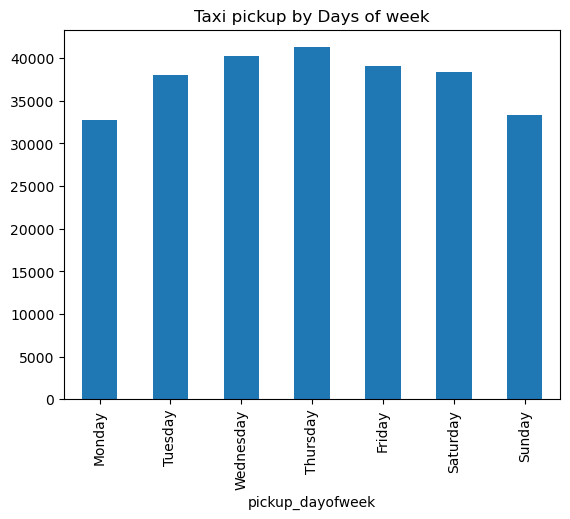

In [114]:
# Find and show the daily trends in taxi pickups (days of the week)
daily_trip = df.groupby('pickup_dayofweek').size()

daily_trip = daily_trip.reindex([
    'Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'
])

daily_trip.plot(kind = "bar", title = "Taxi pickup by Days of week")

<Axes: title={'center': 'Taxi pickup by Month'}, xlabel='pickup_month'>

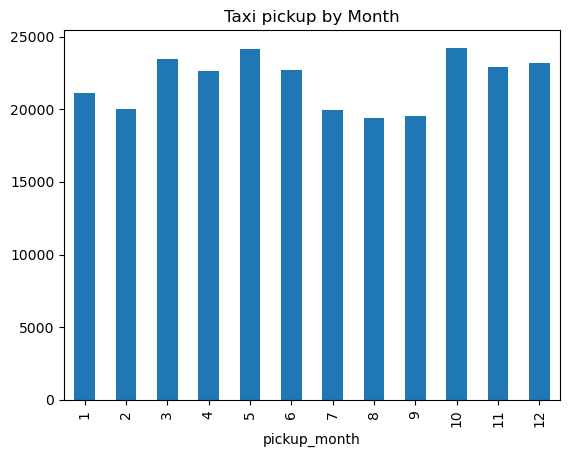

In [116]:
# Show the monthly trends in pickups
monthly_trip = df.groupby('pickup_month').size()

monthly_trip.plot(kind = 'bar', title = 'Taxi pickup by Month')

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [120]:
# Analyse the above parameters
fare_negetive = df[df['fare_amount'] <0]
tip_neagetive = df[df['tip_amount'] <0]
total_amt_negetive = df[df['total_amount']<0]
trip_negetive = df[df['trip_distance']<0]

print(fare_negetive)
print(tip_neagetive)
print(total_amt_negetive)
print(trip_negetive)

Empty DataFrame
Columns: [VendorID, tpep_pickup_datetime, tpep_dropoff_datetime, passenger_count, trip_distance, RatecodeID, store_and_fwd_flag, PULocationID, DOLocationID, payment_type, fare_amount, extra, mta_tax, tip_amount, tolls_amount, improvement_surcharge, total_amount, congestion_surcharge, airport_fee, trip_duration, pickup_hour, pickup_dayofweek, pickup_month]
Index: []

[0 rows x 23 columns]
Empty DataFrame
Columns: [VendorID, tpep_pickup_datetime, tpep_dropoff_datetime, passenger_count, trip_distance, RatecodeID, store_and_fwd_flag, PULocationID, DOLocationID, payment_type, fare_amount, extra, mta_tax, tip_amount, tolls_amount, improvement_surcharge, total_amount, congestion_surcharge, airport_fee, trip_duration, pickup_hour, pickup_dayofweek, pickup_month]
Index: []

[0 rows x 23 columns]
Empty DataFrame
Columns: [VendorID, tpep_pickup_datetime, tpep_dropoff_datetime, passenger_count, trip_distance, RatecodeID, store_and_fwd_flag, PULocationID, DOLocationID, payment_type,

Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [124]:
# Create a df with non zero entries for the selected parameters.
df_nonzero = df[
    (df['fare_amount']>0) &
    (df['tip_amount']>0) &
    (df['total_amount']>0)
]

print(df_nonzero.shape)

(202718, 23)


**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

pickup_month
1     579382.62
2     548056.89
3     660770.22
4     645795.73
5     711898.33
6     670124.97
7     575295.74
8     562920.74
9     593460.90
10    723405.97
11    662093.35
12    671993.49
Name: total_amount, dtype: float64


<Axes: title={'center': 'Pickup Month By total_amount'}, xlabel='pickup_month'>

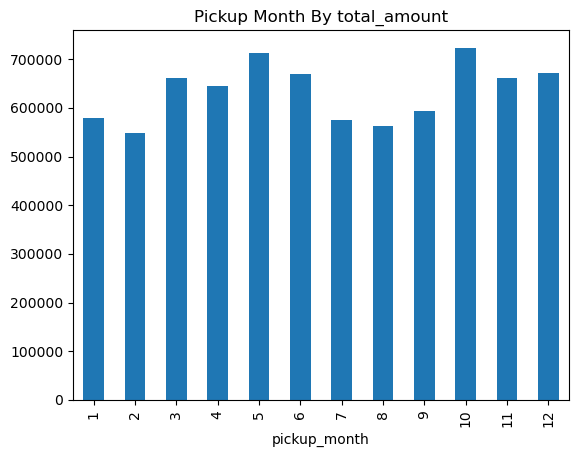

In [127]:
# Group data by month and analyse monthly revenue
monthly_revenue = df.groupby('pickup_month')['total_amount'].sum()
print(monthly_revenue)
monthly_revenue.plot(kind = 'bar', title = 'Pickup Month By total_amount')

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

pickup_qtr
1    1788209.73
2    2027819.03
3    1731677.38
4    2057492.81
Name: total_amount, dtype: float64
pickup_qtr
1    23.512991
2    26.663590
3    22.769653
4    27.053767
Name: total_amount, dtype: float64


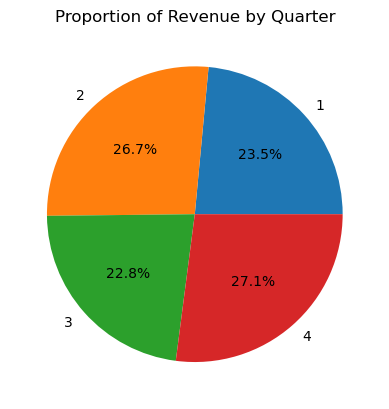

In [132]:
# Calculate proportion of each quarter
df["pickup_qtr"] = pd.to_datetime(df['tpep_pickup_datetime']).dt.quarter 

## revenur by quarter
qtr_revenue = df.groupby('pickup_qtr')['total_amount'].sum()
print(qtr_revenue)

## proportion
qtr_percentage = (qtr_revenue/qtr_revenue.sum()) * 100
print(qtr_percentage)

# Plot
plt.figure()
qtr_percentage.plot(kind='pie', autopct='%1.1f%%')
plt.title('Proportion of Revenue by Quarter')
plt.ylabel('')
plt.show()

**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

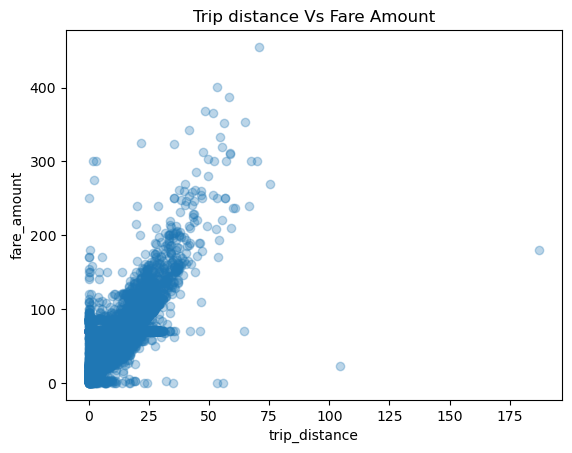

Correlation between trip distance and fare amount: 0.9409134170440064


In [135]:
# Show how trip fare is affected by distance
df_list = df[df['trip_distance']>0]

plt.figure()
plt.scatter(df_list['trip_distance'], df_list['fare_amount'], alpha=0.3)
plt.xlabel('trip_distance')
plt.ylabel('fare_amount')
plt.title('Trip distance Vs Fare Amount')
plt.show()

# Correlation
correlation = df_list['trip_distance'].corr(df_list['fare_amount'])
print("Correlation between trip distance and fare amount:", correlation)


**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

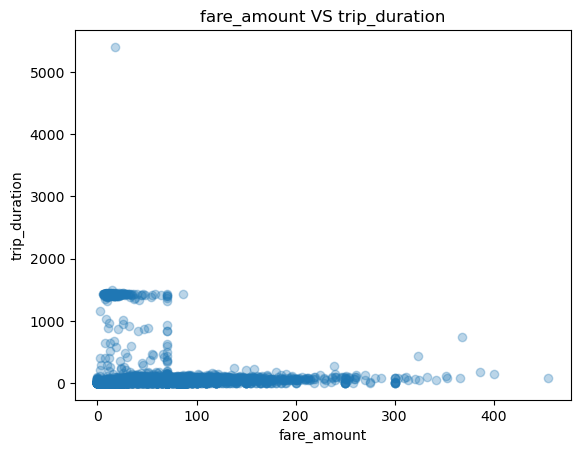

Correlation between trip duration and fare amount: 0.2728592613593254


In [138]:
# Show relationship between fare and trip duration
df_time = df[df['trip_duration']>0].copy()

plt.figure()
plt.scatter(df_time['fare_amount'], df_time['trip_duration'], alpha=0.3)
plt.xlabel('fare_amount')
plt.ylabel('trip_duration')
plt.title('fare_amount VS trip_duration')
plt.show()

# Correlation
correlation = df_time['trip_duration'].corr(df_time['fare_amount'])
print("Correlation between trip duration and fare amount:", correlation)

In [139]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration,pickup_hour,pickup_dayofweek,pickup_month,pickup_qtr
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1,7.74,1,N,138,256,2,...,0.0,1.0,41.15,0.0,1.25,15.950000,0,Sunday,1,1
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2,1.24,1,N,161,237,1,...,0.0,1.0,15.48,2.5,0.00,5.083333,0,Sunday,1,1
2,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3,1.44,1,N,237,141,2,...,0.0,1.0,16.40,2.5,0.00,10.550000,0,Sunday,1,1
3,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1,0.54,1,N,143,142,2,...,0.0,1.0,11.50,2.5,0.00,5.416667,0,Sunday,1,1
4,2,2023-01-01 00:43:00,2023-01-01 01:01:00,1,19.24,1,N,66,107,0,...,0.0,1.0,35.57,2.5,0.00,18.000000,0,Sunday,1,1


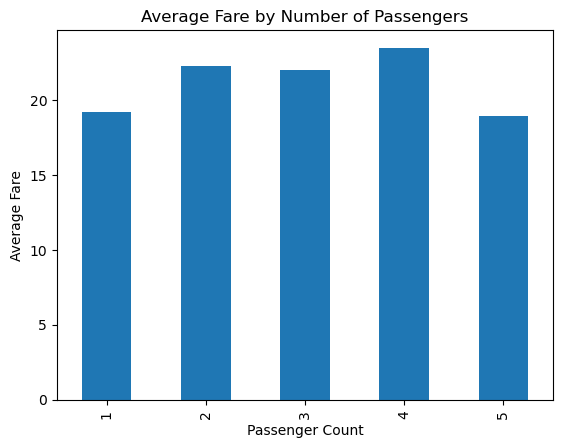

Correlation between passenger_count and fare amount: 0.05062421960313763


In [142]:
# Show relationship between fare and number of passengers
df_fare = df[df['passenger_count'] >0].copy()

avg_fare_pass = df_fare.groupby('passenger_count')['fare_amount'].mean()

plt.figure()
avg_fare_pass.plot(kind='bar')
plt.xlabel("Passenger Count")
plt.ylabel("Average Fare")
plt.title("Average Fare by Number of Passengers")
plt.show()

## Correlation
correlation = df_fare['passenger_count'].corr(df_fare['fare_amount'])
print("Correlation between passenger_count and fare amount:", correlation)


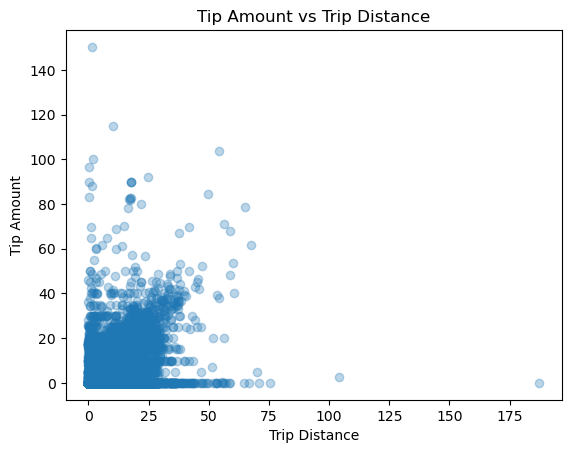

Correlation between trip distance and tip amount: 0.5876488424598284


In [144]:
# Show relationship between tip and trip distance
df_tip = df[df['trip_distance'] > 0].copy()

plt.figure()
plt.scatter(df_tip['trip_distance'], df_tip['tip_amount'], alpha=0.3)
plt.xlabel("Trip Distance")
plt.ylabel("Tip Amount")
plt.title("Tip Amount vs Trip Distance")
plt.show()

# Correlation
correlation = df_tip['trip_distance'].corr(df_tip['tip_amount'])
print("Correlation between trip distance and tip amount:", correlation)


**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

payment_type
1    207214
2     44061
0      8828
4      1907
3      1216
Name: count, dtype: int64
payment_type
1    78.720947
2    16.738848
0     3.353772
4     0.724473
3     0.461960
Name: proportion, dtype: float64


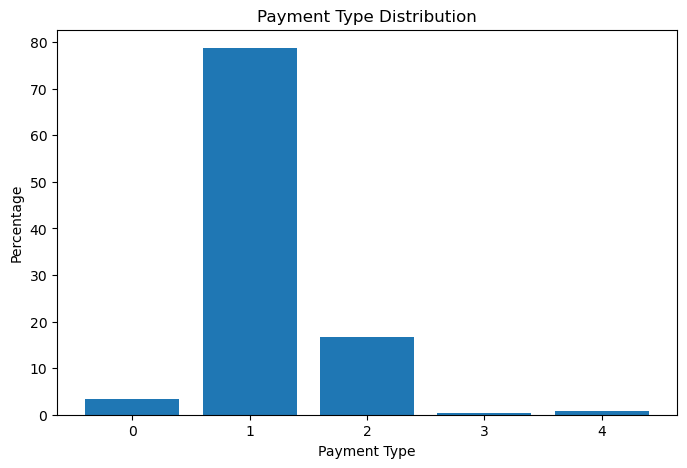

In [161]:
# Analyse the distribution of different payment types (payment_type).
payment_counts = df['payment_type'].value_counts()
print(payment_counts)
payment_percent = df['payment_type'].value_counts(normalize=True) * 100
print(payment_percent)

plt.figure(figsize=(8,5))
plt.bar(payment_percent.index, payment_percent.values)
plt.xlabel("Payment Type")
plt.ylabel("Percentage")
plt.title("Payment Type Distribution")
plt.show()

- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [167]:
import sys
print(sys.executable)

C:\Users\Lenovo\anaconda3\python.exe


In [169]:
import sys
!{sys.executable} -m pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [171]:
import geopandas as gpd

In [172]:
# Read the shapefile using geopandas
zones = gpd.read_file(r"D:\IIITB\NYC Taxi EDA Project\Datasets and Dictionary-NYC\Datasets and Dictionary\taxi_zones\taxi_zones.shp") # read the .shp file using gpd
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB
None


<Axes: >

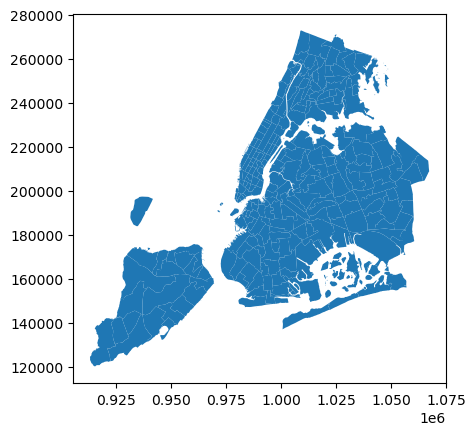

In [174]:
print(zones.info())
zones.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [187]:
# Merge zones and trip records using locationID and PULocationID
merge_df = df.merge(zones, left_on='PULocationID', right_on='LocationID', how='left')
merge_df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,pickup_dayofweek,pickup_month,pickup_qtr,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1,7.74,1,N,138,256,2,...,Sunday,1,1,138.0,0.107467,0.000537,LaGuardia Airport,138.0,Queens,"MULTIPOLYGON (((1019904.219 225677.983, 102031..."
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2,1.24,1,N,161,237,1,...,Sunday,1,1,161.0,0.035804,0.000072,Midtown Center,161.0,Manhattan,"POLYGON ((991081.026 214453.698, 990952.644 21..."
2,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3,1.44,1,N,237,141,2,...,Sunday,1,1,237.0,0.042213,0.000096,Upper East Side South,237.0,Manhattan,"POLYGON ((993633.442 216961.016, 993507.232 21..."
3,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1,0.54,1,N,143,142,2,...,Sunday,1,1,143.0,0.054180,0.000151,Lincoln Square West,143.0,Manhattan,"POLYGON ((989338.1 223572.253, 989368.225 2235..."
4,2,2023-01-01 00:43:00,2023-01-01 01:01:00,1,19.24,1,N,66,107,0,...,Sunday,1,1,66.0,0.054633,0.000108,DUMBO/Vinegar Hill,66.0,Brooklyn,"POLYGON ((990055.507 196472.349, 990004.46 196..."


In [189]:
merge_df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'airport_fee', 'trip_duration',
       'pickup_hour', 'pickup_dayofweek', 'pickup_month', 'pickup_qtr',
       'OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough',
       'geometry'],
      dtype='object')

**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [192]:
# Group data by location and calculate the number of trips
trips_per_location = merge_df.groupby('PULocationID').size().reset_index(name='total_trips')
trips_per_location.head(10)

,PULocationID,total_trips
0,1,37
1,3,9
2,4,308
3,5,1
4,6,3
5,7,136
6,9,3
7,10,81
8,11,5
9,12,110


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [195]:
# Merge trip counts back to the zones GeoDataFrame
zones = zones.merge(trips_per_location, left_on = 'LocationID', 
                                        right_on = 'PULocationID', how='left')
zones.head(3)

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,PULocationID,total_trips
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19...",1.0,37.0
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343...",NaN,NaN
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",3.0,9.0


In [197]:
zones.isnull().sum()

OBJECTID         0
Shape_Leng       0
Shape_Area       0
zone             0
LocationID       0
borough          0
geometry         0
PULocationID    24
total_trips     24
dtype: int64

In [199]:
## filling the null values for total trips
zones['total_trips'] = zones['total_trips'].fillna(0)

## Dropping the PULocationID is unneccesary column
zones = zones.drop(columns=['PULocationID'])

The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

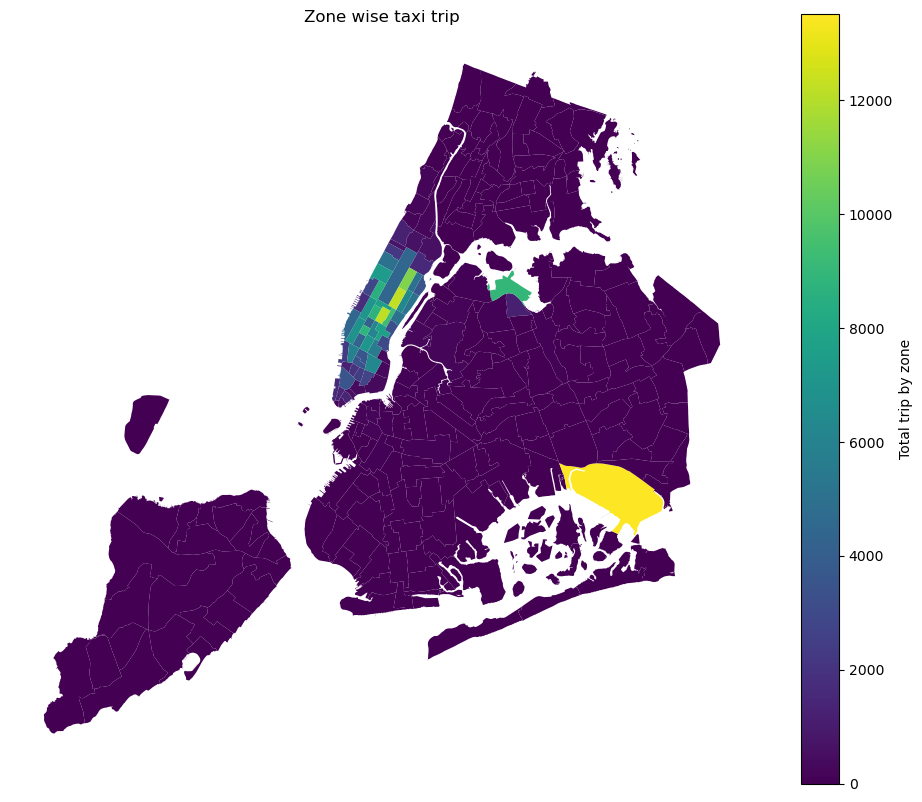

In [208]:
# Define figure and axis
fig, ax = plt.subplots(1, 1, figsize = (12, 10))

# Plot the map and display it
zones.plot(
    column = 'total_trips',
    ax = ax,
    legend = True,
    legend_kwds = {'label': 'Total trip by zone', 'orientation':'vertical'}
)
ax.set_title('Zone wise taxi trip')
ax.axis('off')
plt.show()


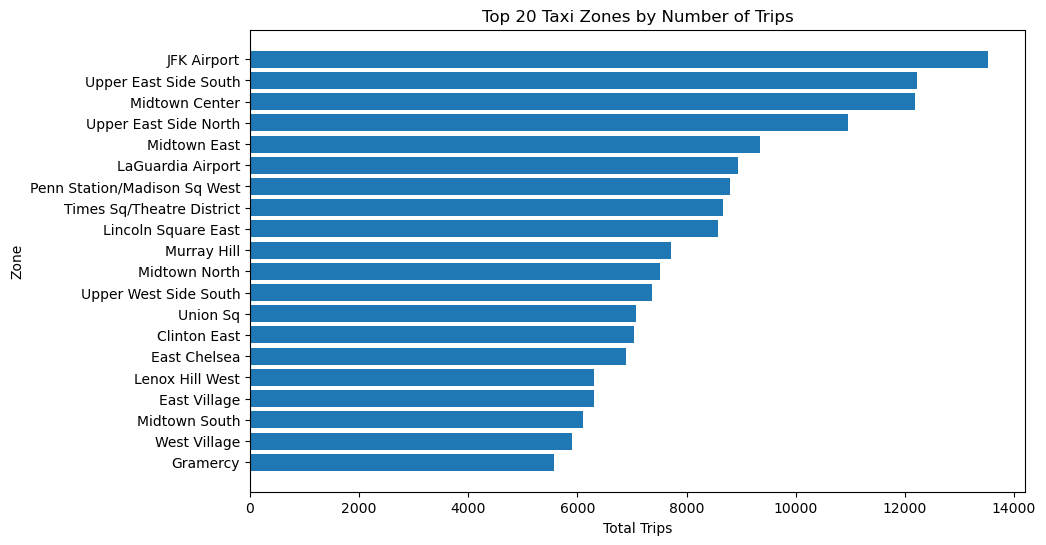

In [216]:
# can you try displaying the zones DF sorted by the number of trips?
top20 = zones.sort_values(by='total_trips', ascending=False).head(20) #we are plotting too many zones on the X-axis, so labels overlap,I have showing top20.

plt.figure(figsize=(10,6))
plt.barh(top20['zone'], top20['total_trips'])
plt.xlabel("Total Trips")
plt.ylabel("Zone")
plt.title("Top 20 Taxi Zones by Number of Trips")
plt.gca().invert_yaxis()
plt.show()

Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [226]:
df.head(2)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration,pickup_hour,pickup_dayofweek,pickup_month,pickup_qtr
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1,7.74,1,N,138,256,2,...,0.0,1.0,41.15,0.0,1.25,15.950000,0,Sunday,1,1
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2,1.24,1,N,161,237,1,...,0.0,1.0,15.48,2.5,0.00,5.083333,0,Sunday,1,1


In [228]:
# Find routes which have the slowest speeds at different times of the day
df_route = df[
    (df['trip_distance'] > 0) &
    (df['trip_duration'] > 0)
].copy()

route_speed = df_route.groupby(
    ['PULocationID','DOLocationID','pickup_hour']).agg({'trip_distance': 'mean', 'trip_duration':'mean'}).reset_index()

route_speed['avg_speed'] = route_speed['trip_distance'] / (route_speed['trip_duration'] / 60)

slowest_routes = route_speed.loc[
    route_speed.groupby('pickup_hour')['avg_speed'].idxmin()
]

slowest_routes = slowest_routes.sort_values('pickup_hour')
slowest_routes.head()


,PULocationID,DOLocationID,pickup_hour,trip_distance,trip_duration,avg_speed
12120,88,144,0,1.780000,1425.466667,0.074923
39491,164,263,1,3.488000,296.023333,0.706971
45698,229,137,2,1.940000,1434.250000,0.081157
31929,148,148,3,0.756429,105.221429,0.431335
46646,230,51,4,16.960000,1417.666667,0.717799


How does identifying high-traffic, high-demand routes help us?

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

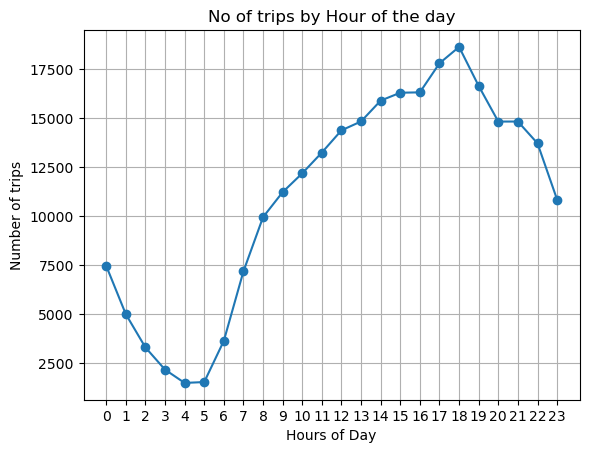

Busiest Hour: 18
Number of Trips: 18624


In [232]:
# Visualise the number of trips per hour and find the busiest hour
trips_per_hour = df.groupby('pickup_hour').size().reset_index(name = 'total_trips')
trips_per_hour.head()

plt.figure()
plt.plot(trips_per_hour['pickup_hour'], trips_per_hour['total_trips'], marker = 'o')
plt.xlabel('Hours of Day')
plt.ylabel('Number of trips')
plt.title('No of trips by Hour of the day')
plt.xticks(range(0,24))
plt.grid()
plt.show()

busiest_hour = trips_per_hour.loc[trips_per_hour['total_trips'].idxmax()]

print("Busiest Hour:", busiest_hour['pickup_hour'])
print("Number of Trips:", busiest_hour['total_trips'])



Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [236]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers
sample_fraction = 0.007

trips_per_hr = df.groupby('pickup_hour').size().reset_index(name = 'sample_trips')

trips_per_hr['actual_trips'] = trips_per_hr['sample_trips'] / sample_fraction

top_5_hrs = trips_per_hr.sort_values(by = 'actual_trips', ascending=False).head(5)

top_5_hrs['actual_trips'] = top_5_hrs['actual_trips'].astype(int)

top_5_hrs


,pickup_hour,sample_trips,actual_trips
18,18,18624,2660571
17,17,17789,2541285
19,19,16634,2376285
16,16,16307,2329571
15,15,16288,2326857


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

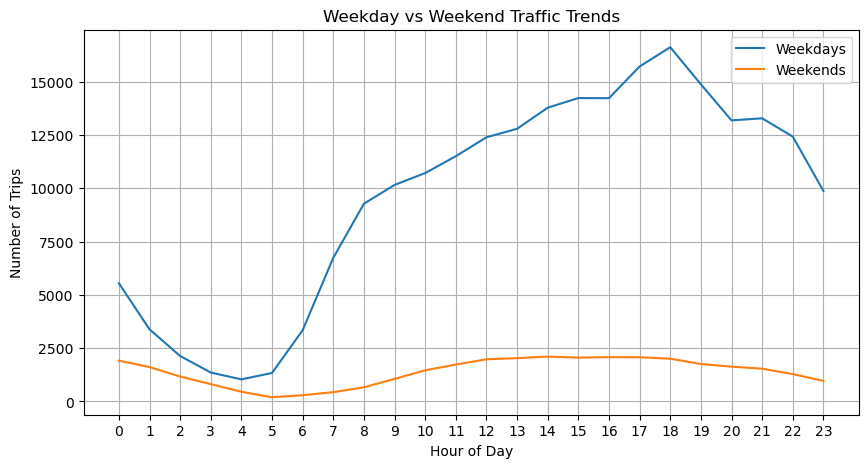

In [239]:
# Compare traffic trends for the week days and weekends
df['is_weekend'] = df['pickup_dayofweek'].isin(['Saterday','Sunday'])

weekday_trips = df[df['is_weekend']==False].groupby('pickup_hour').size()
weekend_trips = df[df['is_weekend']==True].groupby('pickup_hour').size()



plt.figure(figsize=(10,5))

plt.plot(weekday_trips.index, weekday_trips.values, label='Weekdays')
plt.plot(weekend_trips.index, weekend_trips.values, label='Weekends')

plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("Weekday vs Weekend Traffic Trends")
plt.legend()
plt.xticks(range(0,24))
plt.grid()

plt.show()

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

In [247]:
# Find top 10 pickup and dropoff zones
pickup_counts = df.groupby('PULocationID').size().reset_index(name='total_pickups')

pickup_counts = pickup_counts.merge(
    zones[['LocationID','zone','borough']],
    left_on='PULocationID',
    right_on='LocationID',
    how='left'
)

top10_pickups = pickup_counts.sort_values(by='total_pickups', ascending=False).head(10)

top10_pickups[['zone','borough','total_pickups']]



,zone,borough,total_pickups
117,JFK Airport,Queens,13522
214,Upper East Side South,Manhattan,12228
145,Midtown Center,Manhattan,12177
213,Upper East Side North,Manhattan,10961
146,Midtown East,Manhattan,9336
123,LaGuardia Airport,Queens,8944
166,Penn Station/Madison Sq West,Manhattan,8795
207,Times Sq/Theatre District,Manhattan,8674
127,Lincoln Square East,Manhattan,8573
154,Murray Hill,Manhattan,7714


In [249]:
## Top 10 dropoff zones
dropoff_counts = df.groupby('DOLocationID').size().reset_index(name='total_dropoffs')

dropoff_counts = dropoff_counts.merge(
    zones[['LocationID','zone','borough']],
    left_on='DOLocationID',
    right_on='LocationID',
    how='left'
)

top10_dropoffs = dropoff_counts.sort_values(by='total_dropoffs', ascending=False).head(10)

top10_dropoffs[['zone','borough','total_dropoffs']]

,zone,borough,total_dropoffs
226,Upper East Side North,Manhattan,11672
227,Upper East Side South,Manhattan,10912
154,Midtown Center,Manhattan,10201
220,Times Sq/Theatre District,Manhattan,7967
163,Murray Hill,Manhattan,7772
155,Midtown East,Manhattan,7437
135,Lincoln Square East,Manhattan,7400
229,Upper West Side South,Manhattan,7303
134,Lenox Hill West,Manhattan,6766
67,East Chelsea,Manhattan,6724


**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [275]:
# Find the top 10 and bottom 10 pickup/dropoff ratios

total_trips = len(df)

# Pickup counts
pickup_counts = (
    df.groupby('PULocationID')
    .size()
    .reset_index(name='pickups')
)

# Dropoff counts
dropoff_counts = (
    df.groupby('DOLocationID')
    .size()
    .reset_index(name='dropoffs')
)

# Calculate ratios
pickup_counts['pickup_ratio'] = pickup_counts['pickups'] / total_trips
dropoff_counts['dropoff_ratio'] = dropoff_counts['dropoffs'] / total_trips

# Merge with zones
pickup_counts = pickup_counts.merge(
    zones[['LocationID','zone','borough']],
    left_on='PULocationID',
    right_on='LocationID',
    how='left'
)

dropoff_counts = dropoff_counts.merge(
    zones[['LocationID','zone','borough']],
    left_on='DOLocationID',
    right_on='LocationID',
    how='left'
)

In [287]:
#Top10 pickups ratios
top10_pickup_ratio = pickup_counts.sort_values(
    by='pickup_ratio', ascending=False
).head(10)

top10_pickup_ratio.rename(
    columns={'pickup_ratio': 'top_10_pickup_ratio'},
    inplace=True
)

top10_pickup_ratio[['zone','borough','top_10_pickup_ratio']]

,zone,borough,top_10_pickup_ratio
117,JFK Airport,Queens,0.051370
214,Upper East Side South,Manhattan,0.046454
145,Midtown Center,Manhattan,0.046261
213,Upper East Side North,Manhattan,0.041641
146,Midtown East,Manhattan,0.035468
123,LaGuardia Airport,Queens,0.033978
166,Penn Station/Madison Sq West,Manhattan,0.033412
207,Times Sq/Theatre District,Manhattan,0.032953
127,Lincoln Square East,Manhattan,0.032569
154,Murray Hill,Manhattan,0.029306


In [289]:
## Top10 dropoff ratios
top10_dropoff_ratio = dropoff_counts.sort_values(
    by='dropoff_ratio', ascending=False
).head(10)

top10_dropoff_ratio.rename(
    columns={'dropoff_ratio': 'top_10_dropoff_ratio'},
    inplace=True
)

top10_dropoff_ratio[['zone','borough','top_10_dropoff_ratio']]

,zone,borough,top_10_dropoff_ratio
226,Upper East Side North,Manhattan,0.044342
227,Upper East Side South,Manhattan,0.041455
154,Midtown Center,Manhattan,0.038754
220,Times Sq/Theatre District,Manhattan,0.030267
163,Murray Hill,Manhattan,0.029526
155,Midtown East,Manhattan,0.028253
135,Lincoln Square East,Manhattan,0.028113
229,Upper West Side South,Manhattan,0.027744
134,Lenox Hill West,Manhattan,0.025704
67,East Chelsea,Manhattan,0.025545


In [291]:
## Bottom 10 pickups ratios
bottom10_pickup_ratio = pickup_counts.sort_values(
    by='pickup_ratio', ascending=True
).head(10)

bottom10_pickup_ratio.rename(
    columns={'pickup_ratio': 'bottom_10_pickup_ratio'},
    inplace=True
)

bottom10_pickup_ratio[['zone','borough','bottom_10_pickup_ratio']]

,zone,borough,bottom_10_pickup_ratio
167,Port Richmond,Staten Island,0.000004
41,City Island,Bronx,0.000004
113,Inwood Hill Park,Manhattan,0.000004
3,Arden Heights,Staten Island,0.000004
222,West Brighton,Staten Island,0.000004
191,South Beach/Dongan Hills,Staten Island,0.000004
104,Heartland Village/Todt Hill,Staten Island,0.000004
93,Glen Oaks,Queens,0.000004
53,NaN,NaN,0.000004
198,Stapleton,Staten Island,0.000004


In [293]:
## Bottom 10 dropoff ratios
bottom10_dropoff_ratio = dropoff_counts.sort_values(
    by='dropoff_ratio', ascending=True
).head(10)

bottom10_dropoff_ratio.rename(
    columns={'dropoff_ratio': 'bottom_10_dropoff_ratio'},
    inplace=True
)

bottom10_dropoff_ratio[['zone','borough','bottom_10_dropoff_ratio']]

,zone,borough,bottom_10_dropoff_ratio
97,Freshkills Park,Staten Island,0.000004
149,Mariners Harbor,Staten Island,0.000004
56,NaN,NaN,0.000004
178,Port Richmond,Staten Island,0.000004
58,Crotona Park,Bronx,0.000004
175,Pelham Bay Park,Bronx,0.000008
28,Broad Channel,Queens,0.000011
105,Green-Wood Cemetery,Brooklyn,0.000011
241,Westerleigh,Staten Island,0.000011
194,Rossville/Woodrow,Staten Island,0.000011


In [295]:
df.head(2)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,trip_duration,pickup_hour,pickup_dayofweek,pickup_month,pickup_qtr,is_weekend
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1,7.74,1,N,138,256,2,...,1.0,41.15,0.0,1.25,15.950000,0,Sunday,1,1,True
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2,1.24,1,N,161,237,1,...,1.0,15.48,2.5,0.00,5.083333,0,Sunday,1,1,True


In [297]:
merge_df.head(2)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,pickup_dayofweek,pickup_month,pickup_qtr,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1,7.74,1,N,138,256,2,...,Sunday,1,1,138.0,0.107467,0.000537,LaGuardia Airport,138.0,Queens,"MULTIPOLYGON (((1019904.219 225677.983, 102031..."
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2,1.24,1,N,161,237,1,...,Sunday,1,1,161.0,0.035804,0.000072,Midtown Center,161.0,Manhattan,"POLYGON ((991081.026 214453.698, 990952.644 21..."


**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [300]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones
night_df = merge_df[merge_df['pickup_hour'].isin([23,0,1,2,3,4,5])]

top10_night_pickups = (night_df.groupby(['zone','borough']).size().reset_index(name='total_pickups')
                       .sort_values(by='total_pickups',ascending=False).head(10))
top10_night_pickups


    

,zone,borough,total_pickups
53,East Village,Manhattan,2294
84,JFK Airport,Queens,2032
173,West Village,Manhattan,1864
30,Clinton East,Manhattan,1473
101,Lower East Side,Manhattan,1432
157,Times Sq/Theatre District,Manhattan,1232
77,Greenwich Village South,Manhattan,1219
126,Penn Station/Madison Sq West,Manhattan,984
113,Midtown South,Manhattan,900
92,LaGuardia Airport,Queens,881


In [302]:
## Top 10 dropff zones 
merge_drop = df.merge(
    zones,
    left_on='DOLocationID',
    right_on='LocationID'
)

night_drop = merge_drop[merge_drop['pickup_hour'].isin([23,0,1,2,3,4,5])]

top10_night_dropoffs = (
    night_drop.groupby(['zone','borough'])
    .size()
    .reset_index(name='total_dropoffs')
    .sort_values(by='total_dropoffs', ascending=False)
    .head(10)
)

top10_night_dropoffs

,zone,borough,total_dropoffs
72,East Village,Manhattan,1222
43,Clinton East,Manhattan,1029
154,Murray Hill,Manhattan,893
61,East Chelsea,Manhattan,866
95,Gramercy,Manhattan,849
127,Lenox Hill West,Manhattan,780
240,Yorkville West,Manhattan,764
226,West Village,Manhattan,686
82,Flatiron,Manhattan,665
134,Lower East Side,Manhattan,660


Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

In [324]:
# Filter for night hours (11 PM to 5 AM)
night_df = merge_df[merge_df['pickup_hour'].isin([23, 0, 1, 2, 3, 4, 5])]

night_df.head()

day_df = df[~df.index.isin(night_df.index)]

night_revenue = night_df['total_amount'].sum()
day_revenue = day_df['total_amount'].sum()

total_revenue = night_revenue + day_revenue

night_share = (night_revenue / total_revenue) * 100
day_share = (day_revenue / total_revenue) * 100

print("Night Revenue Share:", night_share)
print("Day Revenue Share:", day_share)

Night Revenue Share: 12.351686155764021
Day Revenue Share: 87.64831384423599


##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

In [330]:
# Analyse the fare per mile per passenger for different passenger counts
df_fare = df[
    (df['trip_distance']>0) &
    (df['passenger_count']>0) &
    (df['fare_amount']>0)
].copy()

df_fare['fare_per_passenger'] = (df_fare['fare_amount'] / (df_fare['trip_distance'] * df_fare['passenger_count'].astype(int)))

fare_analysis = (df_fare.groupby('passenger_count')['fare_per_passenger'].mean().reset_index())

fare_analysis

,passenger_count,fare_per_passenger
0,1,10.779463
1,2,6.185374
2,3,4.332130
3,4,5.182434
4,5,1.565300


**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

In [333]:
# Compare the average fare per mile for different days and for different times of the day
df_fare = df[(df['trip_distance'] > 0) & (df['fare_amount'] > 0)].copy()

df_fare['fare_per_mile'] = df_fare['fare_amount'] / df_fare['trip_distance']

fare_by_day = (
    df_fare.groupby('pickup_dayofweek')['fare_per_mile']
    .mean()
    .reset_index()
    .sort_values(by='fare_per_mile', ascending=False)
)

fare_by_day

,pickup_dayofweek,fare_per_mile
4,Thursday,12.764576
3,Sunday,11.837198
6,Wednesday,11.581904
2,Saturday,11.131689
5,Tuesday,10.943397
1,Monday,10.232056
0,Friday,9.945052


**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

In [336]:
# Compare fare per mile for different vendors
df_vendor = df[(df['trip_distance']>0) & (merge_df['fare_amount']>0)].copy()

df_vendor['fare_per_mile'] = df_vendor['fare_amount'] / df_vendor['trip_distance']

fare_vendor = (
    df_vendor.groupby('VendorID')['fare_per_mile']
    .mean()
    .reset_index()
)
fare_vendor.head()


,VendorID,fare_per_mile
0,1,8.010863
1,2,12.402533
2,6,5.050381


**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


In [339]:
# Defining distance tiers
df_tier = df[
    (df['trip_distance']> 0 ) &
    (df['fare_amount'] >0)
].copy()

df_tier['fare_per_mile'] = df_tier['fare_amount'] / df_tier['trip_distance']

def distance_tier(x):
    if x <=2:
        return '0-2 miles'
    elif x <=5:
        return '2-5 miles'
    else:
        return '>5 miles'

df_tier['distance_tier'] = df_tier['trip_distance'].apply(distance_tier)
        
tier_analysis = (
    df_tier.groupby(['VendorID','distance_tier'])['fare_per_mile']
    .mean()
    .reset_index()
)

tier_analysis.head()


,VendorID,distance_tier,fare_per_mile
0,1,0-2 miles,9.749953
1,1,2-5 miles,6.385617
2,1,>5 miles,4.411753
3,2,0-2 miles,18.087303
4,2,2-5 miles,6.533473


##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

In [343]:
#  Analyze tip percentages based on distances, passenger counts and pickup times
df_tip = df[(df['fare_amount'] > 0) & (df['tip_amount'] >= 0)].copy()

df_tip['tip_percentage'] = (df_tip['tip_amount'] / df_tip['fare_amount']) * 100

def distance_tier(x):
    if x <= 2:
        return '0-2 miles'
    elif x <= 5:
        return '2-5 miles'
    else:
        return '>5 miles'

df_tip['distance_tier'] = df_tip['trip_distance'].apply(distance_tier)

tip_by_distance = (
    df_tip.groupby('distance_tier')['tip_percentage']
    .mean()
    .reset_index()
)
print(tip_by_distance.head())

tip_by_passanger_count = (
    df_tip.groupby('passenger_count')['tip_percentage'].mean().reset_index())
print(tip_by_passanger_count.head())

tip_by_hour = (
    df_tip.groupby('pickup_hour')['tip_percentage']
    .mean()
    .reset_index()
)
print(tip_by_hour.head())



  distance_tier  tip_percentage
0     0-2 miles       22.076652
1     2-5 miles       18.583716
2      >5 miles       16.489020
   passenger_count  tip_percentage
0                0       20.958480
1                1       20.377397
2                2       19.678449
3                3       18.901566
4                4       17.278987
   pickup_hour  tip_percentage
0            0       20.206388
1            1       21.039617
2            2       19.667782
3            3       19.771897
4            4       17.413215


Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

In [347]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%
low_tip = df_tip[df_tip['tip_percentage'] < 10]
high_tip = df_tip[df_tip['tip_percentage'] > 25]

comparison = pd.DataFrame({
    'Metric': ['Avg Distance', 'Avg Fare', 'Avg Duration', 'Avg Passenger Count'],
    'Low Tip (<10%)': [
        low_tip['trip_distance'].mean(),
        low_tip['fare_amount'].mean(),
        low_tip['trip_duration'].mean(),
        low_tip['passenger_count'].mean()
    ],
    'High Tip (>25%)': [
        high_tip['trip_distance'].mean(),
        high_tip['fare_amount'].mean(),
        high_tip['trip_duration'].mean(),
        high_tip['passenger_count'].mean()
    ]
})

print(comparison)


                Metric  Low Tip (<10%)  High Tip (>25%)
0         Avg Distance        3.695083         2.299740
1             Avg Fare       21.689508        14.445913
2         Avg Duration       19.599985        12.624824
3  Avg Passenger Count        1.345121         1.300284


**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

In [350]:
# See how passenger count varies across hours and days
passegner_by_hour = df.groupby('pickup_hour')['passenger_count'].mean().reset_index()

passenger_by_day = df.groupby('pickup_dayofweek')['passenger_count'].mean().reset_index()

print(passegner_by_hour.head())
print(passenger_by_day)


   pickup_hour  passenger_count
0            0         1.347272
1            1         1.377978
2            2         1.360715
3            3         1.329178
4            4         1.260753
  pickup_dayofweek  passenger_count
0           Friday         1.333359
1           Monday         1.289627
2         Saturday         1.401632
3           Sunday         1.392445
4         Thursday         1.275766
5          Tuesday         1.265744
6        Wednesday         1.262534


**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

In [355]:
# How does passenger count vary across zones
passenger_by_zone = (merge_df.groupby(['zone','borough'])['passenger_count'].mean().reset_index().sort_values(by='passenger_count', ascending=False))
passenger_by_zone.head()

,zone,borough,passenger_count
3,Arrochar/Fort Wadsworth,Staten Island,2.000000
58,Dyker Heights,Brooklyn,2.000000
136,Marine Park/Floyd Bennett Field,Brooklyn,2.000000
41,Claremont/Bathgate,Bronx,1.727273
173,Red Hook,Brooklyn,1.680000


In [357]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.

trips_per_zone = (
    df.groupby('PULocationID')
    .size()
    .reset_index(name='total_trips')
)

zones_with_trips = zones.merge(
    trips_per_zone,
    left_on='LocationID',
    right_on='PULocationID',
    how='left'
)


avg_passenger_zone = (
    df.groupby('PULocationID')['passenger_count']
    .mean()
    .reset_index()
)

zones_with_trips = zones_with_trips.merge(
    avg_passenger_zone,
    left_on='LocationID',
    right_on='PULocationID',
    how='left'
)

zones_with_trips.rename(
    columns={'passenger_count': 'avg_passenger_count'},
    inplace=True
)

zones_with_trips.drop(columns=['total_trips_y','PULocationID_y'], inplace=True)

# Fill NaN
zones_with_trips['avg_passenger_count'] = zones_with_trips['avg_passenger_count'].fillna(0)

zones_with_trips.head()


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,total_trips_x,PULocationID_x,avg_passenger_count
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19...",37.0,1.0,1.621622
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343...",0.0,NaN,0.000000
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",9.0,3.0,1.111111
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20...",308.0,4.0,1.262987
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144...",1.0,5.0,1.000000


Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

extra applied in 158568 trips
mta_tax applied in 260794 trips
improvement_surcharge applied in 263112 trips
congestion_surcharge applied in 243690 trips
airport_fee applied in 22441 trips
tolls_amount applied in 21318 trips


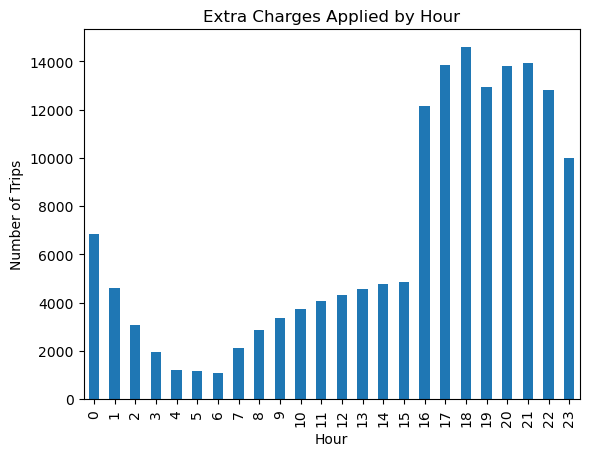

,PULocationID,extra_trips,LocationID,zone,borough
81,138,8838,138.0,LaGuardia Airport,Queens
97,161,7812,161.0,Midtown Center,Manhattan
146,237,6975,237.0,Upper East Side South,Manhattan
76,132,6707,132.0,JFK Airport,Queens
140,230,5746,230.0,Times Sq/Theatre District,Manhattan
145,236,5743,236.0,Upper East Side North,Manhattan
98,162,5732,162.0,Midtown East,Manhattan
84,142,5270,142.0,Lincoln Square East,Manhattan
112,186,5152,186.0,Penn Station/Madison Sq West,Manhattan
99,163,4671,163.0,Midtown North,Manhattan


In [361]:
# How often is each surcharge applied?
surcharge_cols = [
    'extra',
    'mta_tax',
    'improvement_surcharge',
    'congestion_surcharge',
    'airport_fee',
    'tolls_amount'
]

for col in surcharge_cols:
    count = (df[col] > 0).sum()
    print(col, "applied in", count, "trips")

## Extra Charges By Hour
extra_by_hour = df[df['extra'] > 0].groupby('pickup_hour').size()

extra_by_hour.plot(kind='bar')
plt.title("Extra Charges Applied by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Trips")
plt.show()

## Extra charges By PickupZone
extra_zone = df[df['extra'] > 0].groupby('PULocationID').size().reset_index(name='extra_trips')

extra_zone = extra_zone.merge(
    zones[['LocationID','zone','borough']],
    left_on='PULocationID',
    right_on='LocationID',
    how='left'
)
extra_zone.sort_values(by='extra_trips', ascending=False).head(10)



In [363]:
## Extra charges By Dropoff Zone
extra_zone = df[df['extra'] > 0].groupby('DOLocationID').size().reset_index(name='extra_trips')

extra_zone = extra_zone.merge(
    zones[['LocationID','zone','borough']],
    left_on='DOLocationID',
    right_on='LocationID',
    how='left'
)
extra_zone.sort_values(by='extra_trips', ascending=False).head(10)


,DOLocationID,extra_trips,LocationID,zone,borough
225,236,6733,236.0,Upper East Side North,Manhattan
226,237,5952,237.0,Upper East Side South,Manhattan
153,161,5040,161.0,Midtown Center,Manhattan
162,170,4712,170.0,Murray Hill,Manhattan
219,230,4603,230.0,Times Sq/Theatre District,Manhattan
228,239,4496,239.0,Upper West Side South,Manhattan
134,142,4392,142.0,Lincoln Square East,Manhattan
133,141,4359,141.0,Lenox Hill West,Manhattan
45,48,4191,48.0,Clinton East,Manhattan
154,162,3994,162.0,Midtown East,Manhattan


## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

Based on the analysis of trip demand, trip duration, traffic speed, and zone-wise trip distribution, taxi operations can be improved by placing more taxis in areas where demand is high and moving taxis based on demand at different times of the day. Slow traffic routes during peak hours should be avoided to reduce trip time. More taxis should be available during the busiest hours to meet customer demand. Ride-sharing can be encouraged in zones where more passengers usually travel together. These steps can help reduce the time taxis spend without passengers, increase the number of trips per taxi, reduce customer waiting time, and improve overall revenue and operational efficiency.

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

From the zone and time-based analysis, it was observed that demand varies across different zones and different times such as peak hours, weekends, and night hours. Taxis should be strategically positioned in high-demand pickup zones during peak hours, residential areas during morning hours, commercial areas during evening hours, and airport or entertainment zones during night hours. During low-demand periods, taxis should be repositioned to nearby high-demand zones instead of waiting in low-demand areas. This strategy will help reduce passenger waiting time, increase taxi utilization, and improve revenue generation.

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

Based on fare per mile, trip distance, demand patterns, and time-based revenue analysis, pricing strategies can be adjusted using a data-driven approach. Higher pricing can be applied during peak demand hours, busy zones, and high-traffic periods where demand is high. For short trips, minimum fare pricing can be optimized since fare per mile is higher for shorter distances. Discounts or promotional pricing can be introduced during low-demand hours to increase trip volume. Nighttime and airport trips can include additional charges since demand is consistent during those periods. These pricing adjustments can help maximize revenue while still remaining competitive with other vendors.